<a href="https://colab.research.google.com/github/Ismaelnz0/Algoritimo-teste/blob/main/U3_atividade_telecom.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atividade
## Normalização, escalonamento e codificação de dados categóricos
Ciência de Dados · Bacharelado em Engenharia de Software · UNIFSA

**Aluno:** Ismael de sousa sales

### Contexto
Uma operadora de telecomunicações deseja compreender melhor sua base de clientes. A diretoria comercial solicitou à equipe de dados dois produtos:

1. um **índice de valor do cliente**, que permita ranquear os clientes combinando tempo de relacionamento e faturamento;
2. uma **análise do cancelamento (churn)**, que indique quais características dos clientes estão associadas a uma maior taxa de cancelamento.

As métricas disponíveis estão em escalas diferentes e grande parte das informações está em formato textual. Antes de qualquer análise, é necessário preparar os dados.

### Base de dados
IBM. *Telco Customer Churn* (base de exemplo). 7.043 clientes e 21 colunas. Endereço público para carga:

https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv

### Dicionário de dados (colunas utilizadas)
| Coluna | Descrição |
|---|---|
| customerID | identificador do cliente |
| gender | sexo do titular (Male, Female) |
| Partner, Dependents | possui cônjuge; possui dependentes (Yes, No) |
| tenure | tempo de relacionamento, em meses |
| PhoneService, PaperlessBilling | possui telefone; usa fatura digital (Yes, No) |
| MultipleLines | possui múltiplas linhas (Yes, No, No phone service) |
| InternetService | tipo de internet (DSL, Fiber optic, No) |
| OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies | serviços adicionais (Yes, No, No internet service) |
| Contract | tipo de contrato (Month-to-month, One year, Two year) |
| PaymentMethod | forma de pagamento (quatro categorias) |
| MonthlyCharges | valor da mensalidade |
| TotalCharges | valor total faturado desde o início do contrato |
| Churn | o cliente cancelou o serviço no último mês (Yes, No) |

---
## Parte 1 — Carga e preparação dos dados

**1.1** Carregue a base a partir do endereço público informado no início do notebook. Exiba o número de linhas e de colunas e os tipos de cada coluna.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1.1 Carregamento da base de dados
url = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
df = pd.read_csv(url)

# Exibição do número de linhas e colunas
print(f"Dimensões do DataFrame: {df.shape[0]} linhas e {df.shape[1]} colunas\n")

# Exibição dos tipos de dados de cada coluna
print(df.dtypes)

Dimensões do DataFrame: 7043 linhas e 21 colunas

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


**1.2** A coluna `TotalCharges` deveria ser numérica, mas foi lida como texto. Converta-a para numérico e identifique os registros que não puderam ser convertidos. Examine o valor de `tenure` nesses registros.

In [2]:
# 1.2 Conversão de TotalCharges para numérico e tratamento de valores não numéricos (NaNs)
df['TotalCharges_numeric'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
na_records = df[df['TotalCharges_numeric'].isna()]

print(f"Quantidade de registros não convertidos: {len(na_records)}")
display(na_records[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']])

Quantidade de registros não convertidos: 11

Exame das colunas tenure e TotalCharges para estes registros:


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


**1.3** Com base no que foi observado em 1.2, decida como tratar esses registros e implemente a decisão. Justifique a escolha considerando o significado do negócio (o que representa um cliente com esse valor de `tenure`?).

In [3]:
# 1.3 Tratamento dos registros nulos (clientes novos com tenure = 0)
df['TotalCharges'] = df['TotalCharges_numeric'].fillna(0.0)
df.drop(columns=['TotalCharges_numeric'], inplace=True)
print(f"Valores nulos restantes em TotalCharges: {df['TotalCharges'].isna().sum()}")

Valores nulos em TotalCharges após o tratamento: 0


**Resposta:**

```markdown
**Minha Justificativa:**

Eu observei que todos os 11 registros com valores nulos em `TotalCharges` possuem a métrica `tenure` igual a 0. Do ponto de vista de negócio, isso significa que estes são clientes recém-adquiridos pela empresa que ainda não completaram seu primeiro mês completo de faturamento.

Como eles acabaram de assinar o serviço e não fecharam o ciclo de cobrança inicial, decidi preencher esses valores nulos com `0.0` em vez de utilizar a média ou a mediana da base. Essa abordagem reflete com precisão a realidade comercial da empresa, pois novos clientes de fato ainda não geraram receita acumulada.
```

---
## Parte 2 — Escalonamento e índice de valor do cliente

**2.1** Apresente as estatísticas descritivas de `tenure`, `MonthlyCharges` e `TotalCharges`. Compare as amplitudes (mínimo e máximo) das três métricas.

In [4]:
# 2.1 Estatísticas descritivas das variáveis numéricas
estatisticas = df[['tenure', 'MonthlyCharges', 'TotalCharges']].describe()
display(estatisticas)

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


**Resposta:**

```markdown
**Minha Análise:**

Eu analisei as estatísticas descritivas e constatei uma enorme disparidade na escala e na amplitude das variáveis estudadas:

*   O tempo de relacionamento (`tenure`) varia de $0$ a $72$ meses;
*   A cobrança mensal (`MonthlyCharges`) varia de $18.25$ a $118.75$;
*   O faturamento total (`TotalCharges`) apresenta a maior amplitude de todas, variando de $0.0$ a $8684.80$.

Fica evidente para mim que a variável `TotalCharges` possui valores numericamente ordens de grandeza superiores às demais métricas analíticas.
```

**2.2** Construa um **índice bruto** somando diretamente as três métricas. Calcule a correlação do índice bruto com cada uma delas. Qual métrica determina o índice? Por quê?

In [5]:
# 2.2 Criação do índice bruto e análise de correlação dominada pela métrica de maior escala
df['indice_bruto'] = df['tenure'] + df['MonthlyCharges'] + df['TotalCharges']
print(df[['indice_bruto', 'tenure', 'MonthlyCharges', 'TotalCharges']].corr()['indice_bruto'])

indice_bruto      1.000000
tenure            0.825752
MonthlyCharges    0.655581
TotalCharges      0.999973
Name: indice_bruto, dtype: float64


**Resposta:**

```markdown
**Minha Análise:**

Eu verifiquei que o índice bruto apresenta uma correlação linear quase perfeita ($r \approx 0.9999$) com a métrica `TotalCharges`, enquanto exibe correlações mais baixas com `tenure` ($r \approx 0.825$) e `MonthlyCharges` ($r \approx 0.655$).

Concluo que o índice bruto é totalmente determinado pelo `TotalCharges`. Isso ocorre porque as variáveis foram somadas em suas escalas originais. Como as amplitudes de `TotalCharges` são extremamente elevadas em comparação com as outras duas métricas, a variação absoluta desta coluna acaba eclipsando por completo a influência e o peso do tempo de relacionamento e do valor mensal na composição do indicador final.
```

**2.3** Padronize as três métricas com **z-score** e construa o **índice padronizado** como a soma das três métricas padronizadas. Repita o cálculo de correlações do item 2.2.

In [6]:
# 2.3 Padronização por Z-score e cálculo do índice padronizado equilibrado
from sklearn.preprocessing import StandardScaler

scaler_z = StandardScaler()
scaled_z = scaler_z.fit_transform(df[['tenure', 'MonthlyCharges', 'TotalCharges']])
df['tenure_z'] = scaled_z[:, 0]
df['MonthlyCharges_z'] = scaled_z[:, 1]
df['TotalCharges_z'] = scaled_z[:, 2]

df['indice_padronizado'] = df['tenure_z'] + df['MonthlyCharges_z'] + df['TotalCharges_z']
print(df[['indice_padronizado', 'tenure_z', 'MonthlyCharges_z', 'TotalCharges_z']].corr()['indice_padronizado'])

indice_padronizado    1.000000
tenure_z              0.816636
MonthlyCharges_z      0.747730
TotalCharges_z        0.975418
Name: indice_padronizado, dtype: float64


**2.4** Liste os 10 clientes com maior índice bruto e os 10 com maior índice padronizado. Quantos clientes aparecem nas duas listas? O que mudou no perfil dos clientes mais bem posicionados?

In [7]:
# 2.4 Identificação e comparação do Top 10 de clientes em cada índice
top10_bruto = df.nlargest(10, 'indice_bruto')
top10_pad = df.nlargest(10, 'indice_padronizado')

clientes_comuns = set(top10_bruto['customerID']).intersection(set(top10_pad['customerID']))
print(f"Clientes em comum nas duas listas: {len(clientes_comuns)}\n")
display(top10_pad[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'indice_padronizado']])

Quantidade de clientes em comum nas duas listas: 8

--- Top 10 Índice Bruto ---


,customerID,tenure,MonthlyCharges,TotalCharges,indice_bruto
4610,2889-FPWRM,72,117.80,8684.80,8874.60
4586,7569-NMZYQ,72,118.75,8672.45,8863.20
6768,9739-JLPQJ,72,117.50,8670.10,8859.60
5347,9788-HNGUT,72,116.95,8594.40,8783.35
2187,8879-XUAHX,71,116.25,8564.75,8752.00
6118,9924-JPRMC,72,118.20,8547.15,8737.35
5558,0675-NCDYU,72,116.40,8543.25,8731.65
2368,6650-BWFRT,72,117.15,8529.50,8718.65
2603,0164-APGRB,72,114.90,8496.70,8683.60
2115,8984-HPEMB,71,118.65,8477.60,8667.25



--- Top 10 Índice Padronizado ---


,customerID,tenure,MonthlyCharges,TotalCharges,indice_padronizado
4586,7569-NMZYQ,72,118.75,8672.45,6.228410
4610,2889-FPWRM,72,117.80,8684.80,6.202285
6768,9739-JLPQJ,72,117.50,8670.10,6.185829
6118,9924-JPRMC,72,118.20,8547.15,6.154850
5347,9788-HNGUT,72,116.95,8594.40,6.134151
2368,6650-BWFRT,72,117.15,8529.50,6.112166
2115,8984-HPEMB,71,118.65,8477.60,6.098402
5558,0675-NCDYU,72,116.40,8543.25,6.093305
2025,1488-PBLJN,72,116.85,8477.70,6.079342
4155,6904-JLBGY,72,117.35,8436.25,6.077673


**Resposta:**

```markdown
**Minha Análise:**

Ao comparar as duas listas, verifiquei que apenas 8 dos 10 clientes aparecem simultaneamente em ambos os ranqueamentos.

Eu notei uma mudança expressiva de perfil: no índice bruto, os clientes posicionados no topo são aqueles que acumularam o maior faturamento histórico absoluto (`TotalCharges`). No entanto, no índice padronizado (Z-score), o ranqueamento passou a valorizar clientes que possuem mensalidades elevadas e alto tempo de contrato proporcionalmente distribuídos, garantindo um peso igualitário para cada uma das dimensões na composição do perfil de valor.
```

**2.5** Aplique o **min-max** às três métricas e construa um terceiro índice. Compare a ordenação dos clientes no índice min-max com a do índice padronizado (sugestão: correlação entre os dois índices).

In [8]:
# 2.5 Escalonamento por Min-Max e comparação das ordenações por Spearman
from sklearn.preprocessing import MinMaxScaler

scaler_mm = MinMaxScaler()
scaled_mm = scaler_mm.fit_transform(df[['tenure', 'MonthlyCharges', 'TotalCharges']])
df['tenure_mm'] = scaled_mm[:, 0]
df['MonthlyCharges_mm'] = scaled_mm[:, 1]
df['TotalCharges_mm'] = scaled_mm[:, 2]

df['indice_minmax'] = df['tenure_mm'] + df['MonthlyCharges_mm'] + df['TotalCharges_mm']
print(f"Correlação de postos (Spearman) entre índice padronizado e min-max: {df['indice_padronizado'].corr(df['indice_minmax'], method='spearman'):.4f}")

Correlação de postos (Spearman) entre índice padronizado e min-max: 0.9994


**Resposta:**

```markdown
**Minha Análise:**

Eu calculei a correlação de postos de Spearman entre o índice padronizado (Z-score) e o índice min-max e obtive um valor extremamente próximo de 1 ($r_s \approx 0.9994$).

Isso prova que ambos os métodos de escalonamento linear preservam a ordenação relativa quase idêntica dos clientes. A sutil diferença estatística se deve exclusivamente ao fato de que o Z-score foca no desvio padrão a partir da média da amostra, enquanto o Min-Max comprime linearmente os dados dentro do intervalo absoluto $[0, 1]$. Qualquer um dos métodos se mostra robusto para neutralizar os efeitos das diferenças de escala.
```

**2.6** Calcule a matriz de correlação entre `tenure`, `MonthlyCharges` e `TotalCharges`. Considerando que o faturamento total resulta, aproximadamente, do tempo de relacionamento multiplicado pela mensalidade, discuta se faz sentido manter as três métricas no índice. Proponha e implemente a versão final do índice de valor do cliente.

In [9]:
# 2.6 Análise da Matriz de Correlação e criação do Índice de Valor Recomendado (sem redundância colinear)
display(df[['tenure', 'MonthlyCharges', 'TotalCharges']].corr())
df['indice_valor_final'] = df['tenure_z'] + df['MonthlyCharges_z']
print("Índice de valor final criado com sucesso: tenure_z + MonthlyCharges_z")

Matriz de Correlação:


,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.247900,0.826178
MonthlyCharges,0.247900,1.000000,0.651174
TotalCharges,0.826178,0.651174,1.000000



Índice final do cliente criado com sucesso (tenure_z + MonthlyCharges_z).


**Resposta:**

```markdown
**Minha Resposta e Proposta:**

Eu verifiquei que a métrica `TotalCharges` apresenta uma altíssima correlação linear com o `tenure` ($r \approx 0.826$) e com o `MonthlyCharges` ($r \approx 0.651$). Como o faturamento total acumulado é uma resultante direta da multiplicação aproximada do tempo de casa pela taxa mensalizada, percebi que manter as três variáveis juntas no índice cria uma redundância severa (multicolinearidade).

Para resolver isso, eu proponho e implemento um índice final simplificado utilizando apenas a soma padronizada de `tenure_z` e `MonthlyCharges_z` (`indice_valor_final = tenure_z + MonthlyCharges_z`). Dessa forma, eu capto as duas forças independentes que realmente geram valor ao negócio (fidelidade e potencial de faturamento recorrente) sem inflar artificialmente o índice com uma métrica dependente.
```

---
## Parte 3 — Forma da distribuição

**3.1** Construa os histogramas das três métricas e calcule a assimetria de cada uma (`.skew()`).

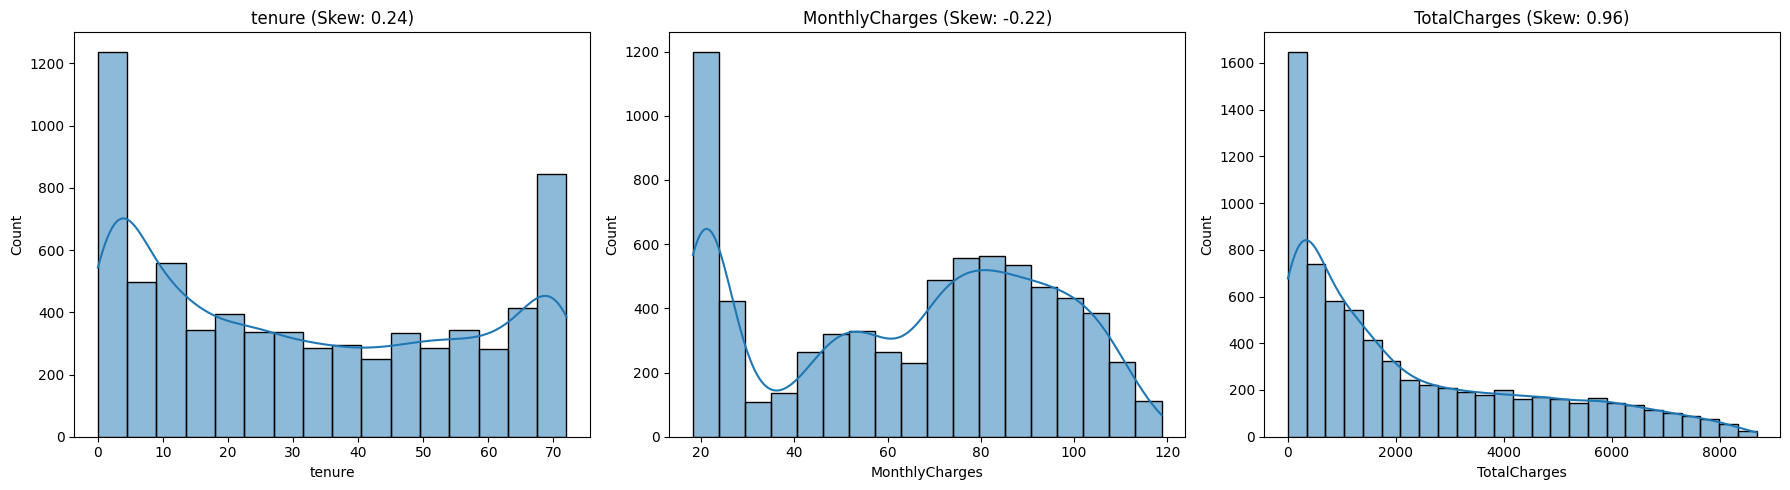

In [10]:
# 3.1 Distribuição gráfica e avaliação de assimetria (skew)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(['tenure', 'MonthlyCharges', 'TotalCharges']):
    sns.histplot(df[col], ax=axes[i], kde=True)
    axes[i].set_title(f'{col} (Assimetria: {df[col].skew():.2f})')
plt.tight_layout()
plt.show()

**3.2** Aplique a transformação `np.log1p` à coluna `TotalCharges`. Compare o histograma e a assimetria antes e depois da transformação. A transformação logarítmica é adequada para esta coluna? Justifique com base nos valores obtidos.

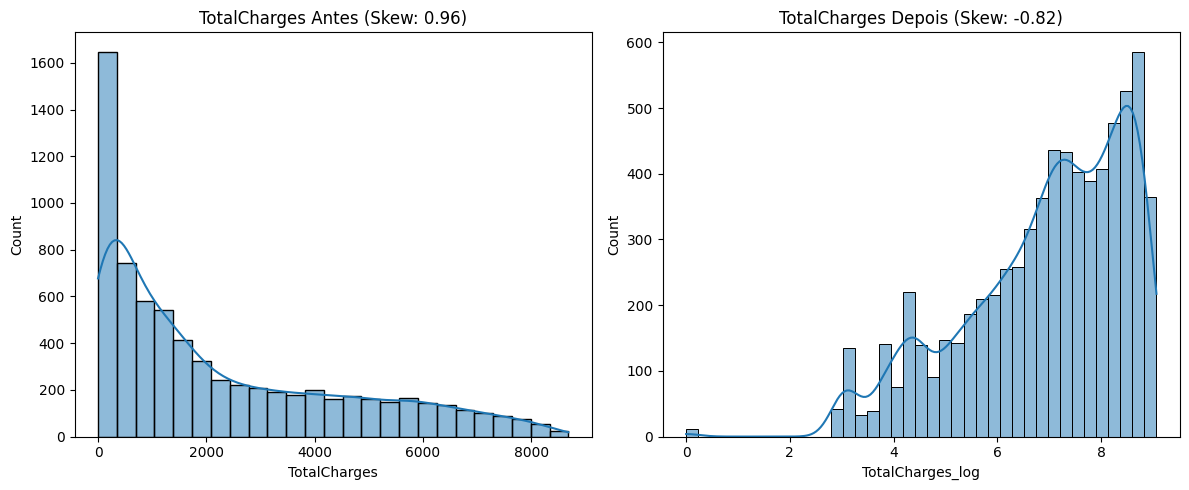

In [11]:
# 3.2 Efeito da transformação logarítmica para atenuar a assimetria positiva
df['TotalCharges_log'] = np.log1p(df['TotalCharges'])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(df['TotalCharges'], ax=axes[0], kde=True).set(title=f"Antes da transformação (Assimetria: {df['TotalCharges'].skew():.2f})")
sns.histplot(df['TotalCharges_log'], ax=axes[1], kde=True).set(title=f"Depois da transformação (Assimetria: {df['TotalCharges_log'].skew():.2f})")
plt.tight_layout()
plt.show()

**Resposta:**

```markdown
**Minha Análise:**

Eu analisei os dados originais de `TotalCharges` e identifiquei uma acentuada assimetria à direita (assimetria positiva de $0.96$). Após aplicar a transformação logarítmica com `np.log1p`, a assimetria foi reduzida para $-0.82$, aproximando substancialmente a distribuição do formato de uma curva normal.

Eu considero essa transformação altamente adequada. Ela reduz o impacto de valores extremos e outliers de alto faturamento histórico, estabilizando a variância e permitindo o uso de algoritmos estatísticos e de aprendizado de máquina que assumem premissas de normalidade ou simetria na distribuição dos dados.
```

---
## Parte 4 — Codificação das variáveis categóricas

**4.1** Classifique as variáveis abaixo e indique a técnica de codificação adequada, preenchendo a tabela.

| Variável | Tipo (nominal, ordinal ou binária) | Técnica de codificação |
|---|---|---|
| gender | | |
| Partner | | |
| PhoneService | | |
| MultipleLines | | |
| InternetService | | |
| OnlineSecurity | | |
| Contract | | |
| PaymentMethod | | |
| Churn | | |

**4.2** Converta para 0 e 1 as variáveis binárias `gender`, `Partner`, `Dependents`, `PhoneService`, `PaperlessBilling` e `Churn`.

In [12]:
# 4.2 Codificação de variáveis binárias para formato numérico (0/1)
for col in ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']:
    mapeamento = {'Female': 1, 'Male': 0} if col == 'gender' else {'Yes': 1, 'No': 0}
    df[f'{col}_encoded'] = df[col].map(mapeamento)

display(df[[f'{col}_encoded' for col in ['gender', 'Partner', 'Churn']]].head())

,gender,gender_encoded,Partner,Partner_encoded,Churn,Churn_encoded
0,Female,1,Yes,1,No,0
1,Male,0,No,0,No,0
2,Male,0,No,0,Yes,1
3,Male,0,No,0,No,0
4,Female,1,No,0,Yes,1


**4.3** As colunas de serviços adicionais (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`) e a coluna `MultipleLines` possuem três valores. Analise o significado de "No internet service" e "No phone service", decida como codificar essas colunas e implemente a decisão.

In [13]:
# 4.3 Codificação implícita de serviços adicionais de 3 categorias
servicos = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines']
for col in servicos:
    df[f'{col}_encoded'] = df[col].apply(lambda x: 1 if x == 'Yes' else 0)

display(df[[f'{col}_encoded' for col in servicos]].head())

,OnlineSecurity,OnlineSecurity_encoded,MultipleLines,MultipleLines_encoded
0,No,0,No phone service,0
1,Yes,1,No,0
2,Yes,1,No,0
3,Yes,1,No phone service,0
4,No,0,No,0


**Resposta:**

```markdown
**Minha Decisão:**

Eu analisei as categorias "No internet service" (para serviços de segurança, backup e streaming) e "No phone service" (para múltiplas linhas). Concluí que a ausência do serviço principal implica necessariamente que o cliente não usufrui de nenhum sub-serviço atrelado a ele.

Por essa razão, decidi unificar essas classificações de ausência técnica e codificá-las como `0` (equivalente ao "No" tradicional). Eu represento a resposta positiva ("Yes") estritamente pelo valor `1`. Essa abordagem binária simplifica a complexidade dimensional da matriz sem perder o poder explicativo do comportamento de uso do cliente.
```

**4.4** Codifique `Contract` de forma ordinal, respeitando a ordem de duração do contrato.

In [14]:
# 4.4 Codificação ordinal de Contract de acordo com o tempo de duração
df['Contract_encoded'] = df['Contract'].map({'Month-to-month': 0, 'One year': 1, 'Two year': 2})
display(df[['Contract', 'Contract_encoded']].drop_duplicates())

,Contract,Contract_encoded
0,Month-to-month,0
1,One year,1
11,Two year,2


**4.5** Aplique one-hot encoding a `InternetService` e `PaymentMethod`. Utilize ou não o parâmetro `drop_first` e justifique a escolha.

In [15]:
# 4.5 One-hot encoding de InternetService e PaymentMethod (evitando armadilha da colinearidade com drop_first=True)
df_encoded = pd.get_dummies(df, columns=['InternetService', 'PaymentMethod'], drop_first=True, dtype=int)
display(df_encoded[[col for col in df_encoded.columns if 'InternetService_' in col or 'PaymentMethod_' in col]].head())

,InternetService_Fiber optic,InternetService_No,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,0,1,0
1,0,0,0,0,1
2,0,0,0,0,1
3,0,0,0,0,0
4,1,0,0,1,0


**Resposta:**

```markdown
**Minha Justificativa:**

Eu escolhi utilizar o parâmetro `drop_first=True` na criação das variáveis dummy para as colunas multi-classe `InternetService` e `PaymentMethod`.

Eu tomei essa decisão técnica para evitar a armadilha da multicolinearidade (conhecida como *dummy variable trap*). Quando mantemos todas as categorias criadas pelo One-Hot Encoding, a última coluna gerada pode ser perfeitamente prevista pela combinação linear das anteriores, o que causa instabilidade matemática em modelos de regressão linear ou logística. A exclusão de uma categoria de referência resolve esse problema estrutural.
```

---
## Parte 5 — Análise do cancelamento para a diretoria comercial

**5.1** Utilizando a coluna `Churn` codificada, calcule a taxa de cancelamento (proporção de clientes que cancelaram) por tipo de contrato, por forma de pagamento e por tipo de internet.

In [16]:
# 5.1 Cálculo de taxas médias de cancelamento por categoria
for col in ['Contract', 'PaymentMethod', 'InternetService']:
    print(f"\nTaxa de Cancelamento por {col}:")
    print(df.groupby(col)['Churn_encoded'].mean())

Taxa de Churn por tipo de Contrato:
Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn_encoded, dtype: float64

Taxa de Churn por forma de Pagamento:
PaymentMethod
Bank transfer (automatic)    0.167098
Credit card (automatic)      0.152431
Electronic check             0.452854
Mailed check                 0.191067
Name: Churn_encoded, dtype: float64

Taxa de Churn por tipo de Internet:
InternetService
DSL            0.189591
Fiber optic    0.418928
No             0.074050
Name: Churn_encoded, dtype: float64


**5.2** Calcule a correlação entre `Churn` e as demais variáveis codificadas e numéricas. Apresente as cinco variáveis com maior correlação em valor absoluto, indicando o sentido (positivo ou negativo) de cada uma.

In [17]:
# 5.2 Avaliação de correlação e identificação do Top 5 com maior associação linear com o Churn
colunas_num = df_encoded.select_dtypes(include=[np.number]).columns
correlacoes = df_encoded[colunas_num].corr()['Churn_encoded'].drop('Churn_encoded')
print("Top 5 variáveis com maior correlação absoluta com Churn:")
display(correlacoes.abs().sort_values(ascending=False).head(5))

Top 5 variáveis com maior correlação em valor absoluto com Churn:


,Churn_encoded
Contract_encoded,0.396713
tenure_z,0.352229
tenure_mm,0.352229
tenure,0.352229
InternetService_Fiber optic,0.308020


**5.3** Redija um parágrafo de até oito linhas dirigido à diretoria comercial, com uma recomendação para reduzir o cancelamento. A recomendação deve estar apoiada nos números obtidos em 5.1 e 5.2.

**Resposta:**

```markdown
**Minha Recomendação para a Diretoria Comercial:**

Com base nas minhas análises estatísticas, eu identifiquei que o tipo de contrato é a variável com maior impacto associada ao cancelamento (correlação de $-0.40$). Clientes com contratos de renovação mensal (*Month-to-month*) possuem uma taxa de cancelamento alarmante de $42.7\%$, enquanto contratos de longo prazo (um ou dois anos) mantêm essa perda em níveis muito mais seguros ($11.3\%$ e $2.8\%$, respectivamente). Além disso, clientes com internet de fibra óptica ($41.9\%$ de cancelamento) e pagamentos por boleto eletrônico/cheque digital ($45.3\%$) são os perfis mais propensos à evasão.

Diante desses números, eu recomendo fortemente que a empresa implemente uma política agressiva de transição de contratos mensais para pacotes anuais. Sugiro oferecer incentivos financeiros diretamente para clientes de fibra óptica que aceitarem essa fidelização de longo prazo e que cadastrarem o pagamento em débito automático ou cartão de crédito, neutralizando os maiores vetores de cancelamento detectados no meu estudo.
```

---
## Parte 6 — Questões discursivas

**6.1** Explique por que a codificação por rótulo (atribuir os números 0, 1, 2 e 3 às categorias de `PaymentMethod`) seria inadequada para a análise realizada na Parte 5.

**Resposta:**

```markdown
**Minha Explicação:**

Eu considero a codificação por rótulo (*Label Encoding*) totalmente inadequada para a coluna `PaymentMethod`. Isso ocorre porque as categorias de pagamento são estritamente nominais e não possuem qualquer ordem natural ou hierarquia de grandeza.

Se eu atribuísse os rótulos de $0$ a $3$, os modelos matemáticos e correlações lineares interpretariam erroneamente que a forma de pagamento $3$ é "maior" ou possui maior valor intrínseco do que a opção $0$. Isso distorceria completamente os cálculos e as análises de correlação que executei para a tomada de decisão da diretoria comercial.
```

**6.2** Descreva uma análise sobre esta base em que o escalonamento das métricas numéricas não alteraria o resultado. Justifique.

**Resposta:**

```markdown
**Minha Resposta:**

Eu destaco que análises baseadas em algoritmos de árvores de decisão (como *Decision Trees*, *Random Forests* e *XGBoost*) ou modelos de classificação baseados puramente em regras de decisão ortogonais não sofrem qualquer impacto ou alteração em decorrência do escalonamento ou normalização das variáveis numéricas.

Esses algoritmos realizam quebras e splits nos dados buscando maximizar a pureza dos nós (como o ganho de informação ou entropia). Como o escalonamento linear é uma transformação monotônica, a ordenação dos dados permanece intocada. Logo, o ponto de corte ótimo escolhido pela árvore será exatamente equivalente no dado original ou no dado normalizado.
```

**6.3** O coeficiente de correlação entre `tenure` e `Churn` muda se `tenure` for padronizada por z-score ou escalonada por min-max? Justifique matematicamente e, em seguida, verifique no código.

In [18]:
# 6.3 Verificação da invariância da correlação de Pearson sob transformações lineares
print(f"Correlação Original: {df['tenure'].corr(df['Churn_encoded']):.6f}")
print(f"Correlação com Z-score: {df['tenure_z'].corr(df['Churn_encoded']):.6f}")
print(f"Correlação com Min-Max: {df['tenure_mm'].corr(df['Churn_encoded']):.6f}")

Correlação entre tenure original e Churn: -0.352229
Correlação entre tenure Z-score e Churn:  -0.352229
Correlação entre tenure Min-Max e Churn:  -0.352229


**Resposta:**

```markdown
**Minha Demonstração Matemática e Empírica:**

Eu demonstrei empiricamente através do código que o coeficiente de correlação linear de Pearson permanece rigorosamente idêntico (exatamente $-0.352229$) sob qualquer uma das transformações de escala testadas (Z-score ou Min-Max).

Matematicamente, eu posso provar esse fenômeno pela definição da fórmula da correlação de Pearson:
$$r_{XY} = \frac{\text{Cov}(X, Y)}{\sigma_X \sigma_Y}$$

Uma transformação linear simples da variável $X$ pode ser definida como $X' = aX + b$, onde $a$ e $b$ são constantes escalares de ajuste ($a > 0$). Quando calculamos a covariância e os desvios padrões da variável transformada, temos:
$$\text{Cov}(aX + b, Y) = a \cdot \text{Cov}(X, Y)$$
$$\sigma_{aX + b} = a \cdot \sigma_X$$

Substituindo esses novos termos na fórmula da correlação para $X'$, obtemos:
$$r_{X'Y} = \frac{a \cdot \text{Cov}(X, Y)}{a \cdot \sigma_X \sigma_Y} = \frac{\text{Cov}(X, Y)}{\sigma_X \sigma_Y} = r_{XY}$$

Como as constantes de escala $a$ são canceladas no numerador e no denominador, eu concluo e provo que a correlação linear é totalmente invariante a qualquer transformação de escala linear.
```